# Caso 1 — Clustering con Iris (`KMeans`, `DBSCAN`, `SpectralClustering`)
**Curso:** Aprendizaje de Máquina (IX ciclo, grupo B) — UNAP  
**Responsable:** Choquepata Puma Renso Erik

## 1. Librerías y datos

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, SpectralClustering

sys.path.insert(0, str(Path.cwd().parent / "src"))
from clustering_utils import (
    set_minimalist_style,
    evaluate_clustering,
    compute_elbow_and_internal_curves,
    plot_scatter_minimal,
    plot_elbow_and_validation_panel,
    plot_metrics_bar_comparison,
)

set_minimalist_style()

iris = load_iris()
X = StandardScaler().fit_transform(iris.data)
y = iris.target

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
print(f"Muestras: {X.shape[0]} | Características: {X.shape[1]} | Clases: {list(iris.target_names)}")

Muestras: 150 | Características: 4 | Clases: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


## 2. Entrenamiento y métricas

In [2]:
km = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42)
y_km = km.fit_predict(X)
c_pca = pca.transform(km.cluster_centers_)

y_db05 = DBSCAN(eps=0.50, min_samples=5).fit_predict(X)
y_db62 = DBSCAN(eps=0.62, min_samples=5).fit_predict(X)
y_sc = SpectralClustering(n_clusters=3, affinity="nearest_neighbors", n_neighbors=10, random_state=42).fit_predict(X)

df_iris = pd.DataFrame([
    evaluate_clustering(X, y, y_km, "K-Means (k=3)", "Iris", km.inertia_),
    evaluate_clustering(X, y, y_db05, "DBSCAN (eps=0.50)", "Iris"),
    evaluate_clustering(X, y, y_db62, "DBSCAN (eps=0.62)", "Iris"),
    evaluate_clustering(X, y, y_sc, "Spectral (k-NN=10)", "Iris"),
])
display(df_iris)

,Dataset,Modelo,Clusters_Detectados,Puntos_Ruido,Ruido_Pct,ARI,V_Measure,Homogeneidad,Completitud,Silhouette,Davies_Bouldin,Inercia_WCSS
0,Iris,K-Means (k=3),3,0,0.00,0.6201,0.6595,0.6591,0.6598,0.4599,0.8336,139.82
1,Iris,DBSCAN (eps=0.50),2,34,22.67,0.4421,0.5114,0.5005,0.5228,0.6559,0.4942,NaN
2,Iris,DBSCAN (eps=0.62),2,21,14.00,0.4821,0.5566,0.5228,0.5950,0.6365,0.5143,NaN
3,Iris,Spectral (k-NN=10),3,0,0.00,0.6465,0.6838,0.6737,0.6941,0.4593,0.8224,NaN


## 3. Visualización de clusters (PCA 2D)

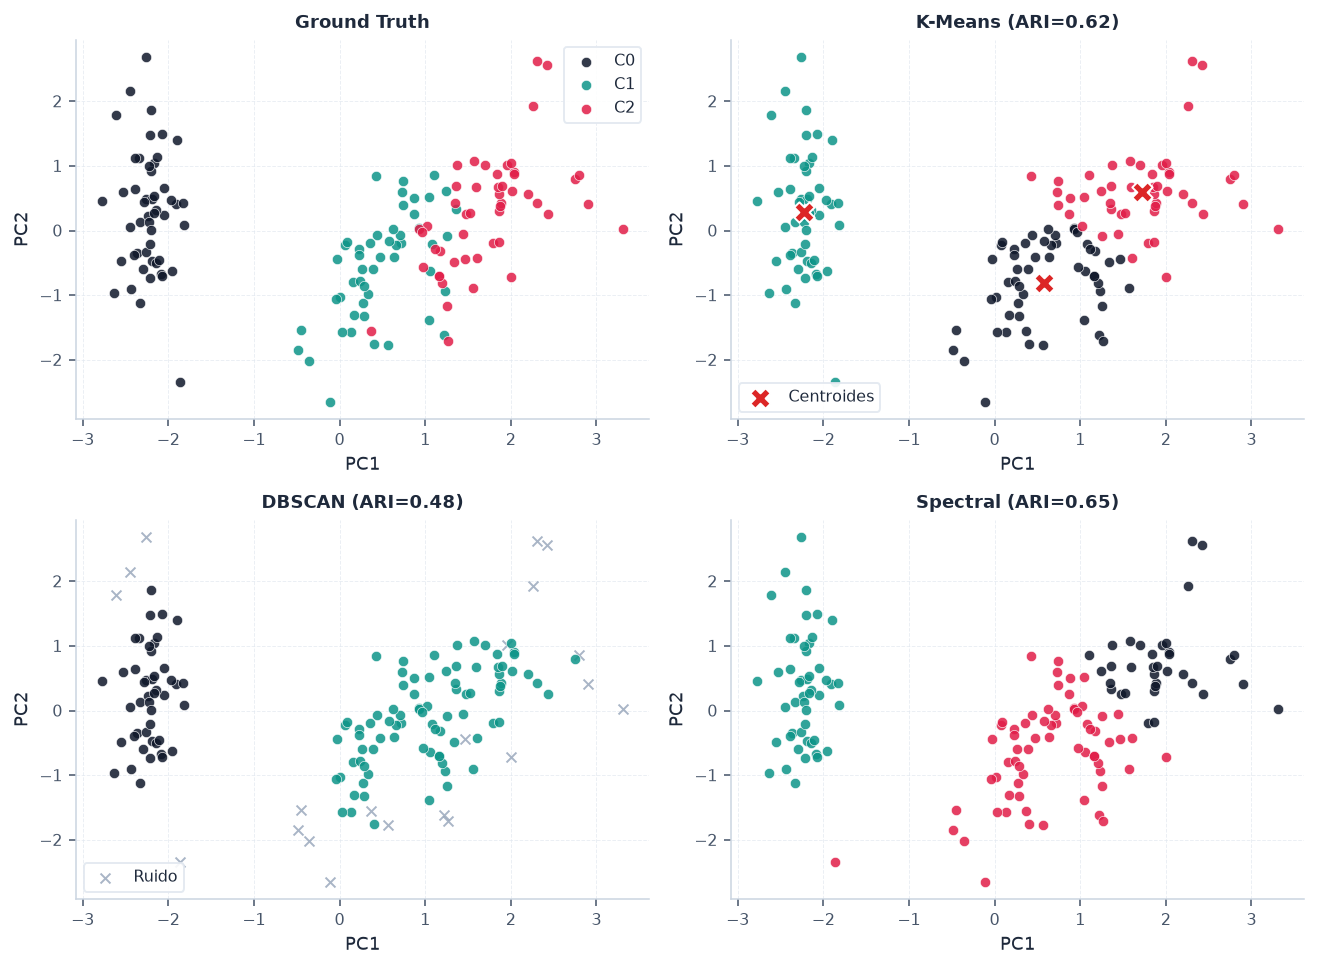

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(9.5, 7.0))
plot_scatter_minimal(axes[0, 0], X_pca, y, "Ground Truth", xlabel="PC1", ylabel="PC2", show_legend=True)
plot_scatter_minimal(axes[0, 1], X_pca, y_km, f"K-Means (ARI={df_iris.loc[0, 'ARI']:.2f})", centroids_2d=c_pca, xlabel="PC1", ylabel="PC2")
plot_scatter_minimal(axes[1, 0], X_pca, y_db62, f"DBSCAN (ARI={df_iris.loc[2, 'ARI']:.2f})", xlabel="PC1", ylabel="PC2")
plot_scatter_minimal(axes[1, 1], X_pca, y_sc, f"Spectral (ARI={df_iris.loc[3, 'ARI']:.2f})", xlabel="PC1", ylabel="PC2")
fig.tight_layout()
plt.show()

## 4. Método del Codo y comparación de métricas

,k,Inercia_WCSS,Silhouette,Davies_Bouldin
0,1,600.0000,NaN,NaN
1,2,222.3617,0.5818,0.5933
2,3,139.8205,0.4599,0.8336
3,4,114.0925,0.3869,0.8698
4,5,90.9275,0.3459,0.9483
5,6,81.5444,0.3171,1.0537
6,7,72.6311,0.3202,0.9905
7,8,62.5406,0.3387,0.9150
8,9,55.1195,0.3424,0.9032


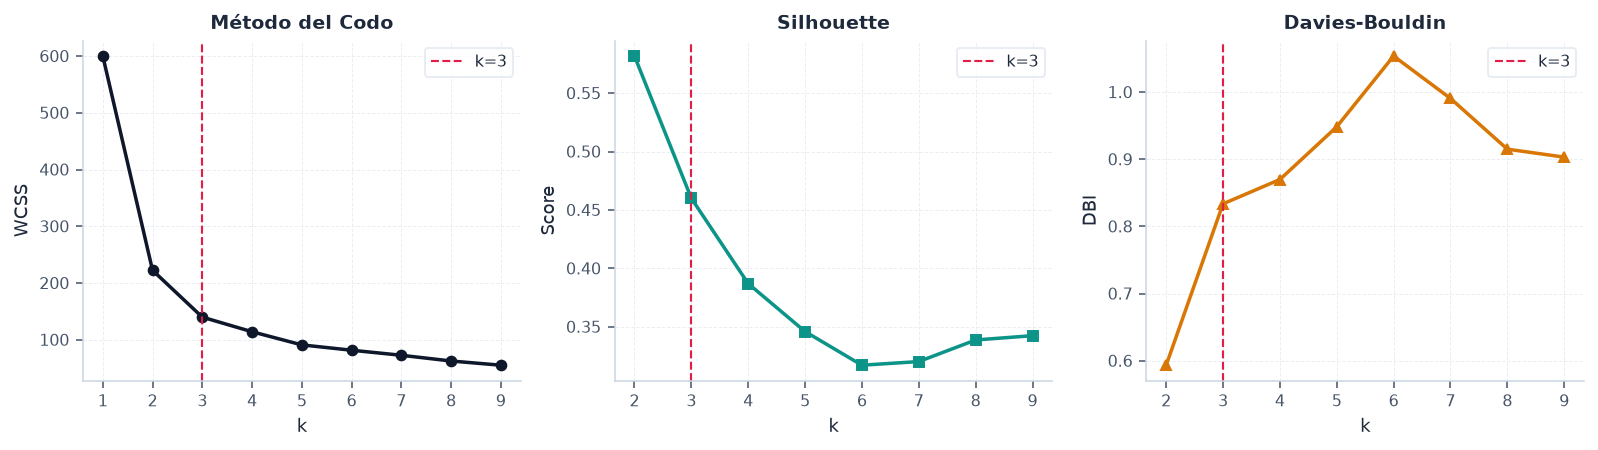

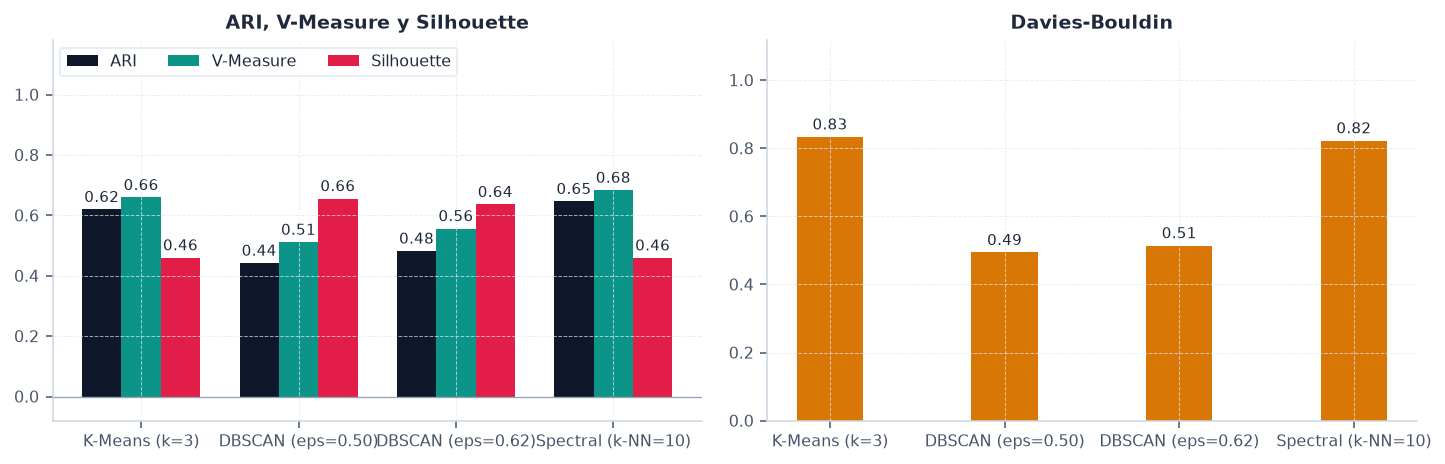

In [4]:
df_curves = compute_elbow_and_internal_curves(X, range(1, 10))
display(df_curves.round(4))

plot_elbow_and_validation_panel(df_curves, optimal_k=3)
plt.show()

plot_metrics_bar_comparison(df_iris)
plt.show()